# 🗓️ Content Planner Agent

**Content Planner Agent** helps a brand plan social media posts from idea to calendar reminder.

The user shares the brand book and brand platform once. The agent saves them to Google Drive (`brand.json`), so it remembers the brand in every session. When asked for a post idea, it checks upcoming public holidays in Georgia (Nager.Date API) and suitable historical events for those dates (Wikipedia "On this day"). It gives a short review of the dates and asks whether to connect the idea to one of them. If no holiday is coming, it builds the idea on the brand alone. It then writes the content idea, a caption draft, hashtags and a visual brief for the designer. The user gives the final caption, visual link, date and time. Only after the user approves does the agent create a Google Calendar event with all the materials. Deleting a post also needs approval.

**Who it helps:** social media managers, small business owners and content creators who find it hard to plan posts and publish on time.

**External services:** Nager.Date (public holidays), Wikipedia "On this day" (historical events), Google Calendar (via a Google Apps Script web app)

**Tools:** `save_brand`, `get_brand`, `get_upcoming_holidays`, `get_on_this_day`, `save_post`, `list_posts`, `create_calendar_reminder`, `delete_post`

**Approval required before:** creating a Google Calendar event, deleting a post

**GitHub:** README, `agent.py`, Streamlit (`app.py`) and CLI (`main.py`) are created in the last section of this notebook.

## ▶️ How to run

1. **Groq key:** create a free key at [console.groq.com/keys](https://console.groq.com/keys).
2. **Google Calendar:** open [script.google.com](https://script.google.com) → New project → paste the code from `apps_script.gs` (last section of this notebook / GitHub) → change `SECRET` → **Deploy → New deployment → Web app** (Execute as: Me, Who has access: Anyone) → copy the Web app URL (ends with `/exec`).
3. **Colab Secrets** (🔑 on the left): add
   - `GROQ_API_KEY` – Groq key
   - `CALENDAR_URL` – Web app URL
   - `CALENDAR_TOKEN` – the `SECRET` value

   and turn on **Notebook access** for all three.
4. **Runtime → Run all.** Allow Google Drive access when asked (brand and posts are stored in `MyDrive/content_planner`).
5. Tests 7–9 create one real Google Calendar event and delete it again.

> Model answers can differ between runs. The evaluation table at the end shows the results of the last run.

## 1. Setup

In [53]:
%pip install -q langgraph langchain-groq requests

In [54]:
import os
from google.colab import userdata

SECRETS = ("GROQ_API_KEY", "CALENDAR_URL", "CALENDAR_TOKEN")
for key in SECRETS:
    os.environ[key] = userdata.get(key)  # error here = the secret is missing or Notebook access is off

print("Secrets loaded:", ", ".join(k for k in SECRETS if os.environ.get(k)))

Secrets loaded: GROQ_API_KEY, CALENDAR_URL, CALENDAR_TOKEN


In [55]:
from langchain_groq import ChatGroq

llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0.3, max_tokens=2000)
print(llm.invoke("Say hello in one short sentence.").content)

Hello!


## 2. Storage (memory between sessions)

Brand and posts are saved as JSON files in Google Drive, so they are not lost when the Colab session ends.

In [56]:
from google.colab import drive
drive.mount("/content/drive")

import os, json

# Brand and posts live in Google Drive, so they survive between Colab sessions
DATA_DIR = "/content/drive/MyDrive/content_planner"
os.makedirs(DATA_DIR, exist_ok=True)
BRAND_FILE = os.path.join(DATA_DIR, "brand.json")
POSTS_FILE = os.path.join(DATA_DIR, "posts.json")


def read_json(path, default):
    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            return json.load(f)
    return default


def write_json(path, data):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=2)


print("Drive ready:", DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive ready: /content/drive/MyDrive/content_planner


## 3. Tools

Every tool has a docstring: the model reads it to decide when and how to call the tool. Each tool is tested directly below its definition.

### 3.1 Brand: `save_brand`, `get_brand`

In [57]:
from langchain_core.tools import tool


@tool
def save_brand(tone: str, audience: str, values: str, colors: str, fonts: str, forbidden: str) -> str:
    """Save the brand profile extracted from the brand book and brand platform.
    Use when the user shares brand book or brand platform text.
    tone: voice and tone; audience: target audience; values: brand values;
    colors: brand colors (names or HEX); fonts: brand fonts;
    forbidden: what the brand must never say or do."""
    brand = {"tone": tone, "audience": audience, "values": values,
             "colors": colors, "fonts": fonts, "forbidden": forbidden}
    write_json(BRAND_FILE, brand)
    return "Brand saved."


@tool
def get_brand() -> dict:
    """Read the saved brand profile. Always call this before writing a post idea."""
    brand = read_json(BRAND_FILE, None)
    if brand is None:
        return {"error": "No brand saved yet. Ask the user for the brand book."}
    return brand


# Test
print(save_brand.invoke({
    "tone": "friendly, short sentences", "audience": "students 18-25 in Tbilisi",
    "values": "creativity, quality", "colors": "#1E3A8A, #F5F5F5",
    "fonts": "Montserrat", "forbidden": "no slang, no competitor names"}))
print(get_brand.invoke({}))

Brand saved.
{'tone': 'friendly, short sentences', 'audience': 'students 18-25 in Tbilisi', 'values': 'creativity, quality', 'colors': '#1E3A8A, #F5F5F5', 'fonts': 'Montserrat', 'forbidden': 'no slang, no competitor names'}


### 3.2 External service 1: Nager.Date – `get_upcoming_holidays`

In [58]:
import requests
from datetime import date, datetime, timedelta


@tool
def get_upcoming_holidays(days: int = 30) -> list:
    """Get public holidays in Georgia (the country) within the next `days` days (Nager.Date API).
    Returns a list of {date, name, local_name, days_left}. An empty list means no holidays in that period."""
    today = date.today()
    end = today + timedelta(days=days)
    result = []
    for year in sorted({today.year, end.year}):
        try:
            r = requests.get(f"https://date.nager.at/api/v3/PublicHolidays/{year}/GE", timeout=20)
        except requests.RequestException as e:
            return [{"error": f"Nager.Date is not reachable: {e}"}]
        if r.status_code != 200 or not r.text.strip():
            return [{"error": f"Nager.Date returned status {r.status_code} for Georgia ({year})"}]
        for h in r.json():
            d = date.fromisoformat(h["date"])
            if today <= d <= end:
                result.append({"date": h["date"], "name": h["name"],
                               "local_name": h["localName"], "days_left": (d - today).days})
    return result


# Test: real API call (60 days)
print(get_upcoming_holidays.invoke({"days": 60}))

[{'date': '2026-11-23', 'name': "Saint George's Day", 'local_name': 'გიორგობა', 'days_left': 1}, {'date': '2027-01-01', 'name': "New Year's Day", 'local_name': 'ახალი წელი', 'days_left': 40}, {'date': '2027-01-02', 'name': "New Year's Day", 'local_name': 'ახალი წელი', 'days_left': 41}, {'date': '2027-01-07', 'name': 'Christmas Day (Orthodox)', 'local_name': 'ქრისტეშობა', 'days_left': 46}, {'date': '2027-01-19', 'name': 'Epiphany (Orthodox)', 'local_name': 'ნათლისღება', 'days_left': 58}]


### 3.3 External service 2: Wikipedia "On this day" – `get_on_this_day`

In [59]:
WIKI_HEADERS = {"User-Agent": "ContentPlannerAgent/0.1 (BTU student project)"}

# An event is kept only if it has a positive word AND no negative word,
# so wars, disasters, scandals and politics do not reach a brand post
POSITIVE_WORDS = ("first", "launch", "invent", "discover", "found", "open", "premiere",
                  "record", "award", "prize", "publish", "release", "complete")
NEGATIVE_WORDS = ("kill", "dead", "death", "dies", "die ", "war", "attack", "bomb", "terror",
                  "earthquake", "fire", "massacre", "murder", "crash", "shoot", "invade",
                  "invasion", "riot", "disaster", "execut", "assassin", "genocide", "explosion",
                  "scandal", "offensive", "apolog", "protest", "coup", "impeach", "trial",
                  "arrest", "sink", "crisis", "president", "elect", "government", "revolution")


@tool
def get_on_this_day(month: int, day: int) -> list:
    """Get up to 5 positive or neutral historical events for this month and day (Wikipedia 'On this day').
    Each item is {"fact": "YEAR: text"}; copy the year exactly as given.
    Wars, disasters, crimes, scandals and politics are filtered out.
    month: 1-12, day: 1-31. Call only for holiday dates or dates the user chose."""
    urls = [
        f"https://en.wikipedia.org/api/rest_v1/feed/onthisday/events/{month:02d}/{day:02d}",
        f"https://api.wikimedia.org/feed/v1/wikipedia/en/onthisday/events/{month:02d}/{day:02d}",
    ]
    for url in urls:
        try:
            r = requests.get(url, headers=WIKI_HEADERS, timeout=20)
        except requests.RequestException:
            continue
        if r.status_code == 200:
            events = r.json().get("events", [])
            safe = []
            for e in events:
                text = (e.get("text") or "").lower()
                if any(p in text for p in POSITIVE_WORDS) and not any(n in text for n in NEGATIVE_WORDS):
                    safe.append({"fact": f'{e.get("year")}: {e.get("text")}'})
            if not safe:
                return [{"info": "No suitable (positive or neutral) events for this date."}]
            return safe[:5]
    return [{"error": "Wikipedia 'On this day' is not reachable"}]


# Test: real API call for 7 January (Orthodox Christmas)
print(get_on_this_day.invoke({"month": 1, "day": 7}))

[{'fact': "1985: Japan Aerospace Exploration Agency launches Sakigake, Japan's first interplanetary spacecraft and the first deep space probe to be launched by any country other than the United States or the Soviet Union."}, {'fact': '1968: Surveyor program: Surveyor 7, the last spacecraft in the Surveyor series, lifts off from Cape Canaveral Launch Complex 36A.'}, {'fact': "1955: Contralto Marian Anderson becomes the first person of color to perform at the Metropolitan Opera in Giuseppe Verdi's Un ballo in maschera."}, {'fact': '1954: Georgetown–IBM experiment: The first public demonstration of a machine translation system is held in New York at the head office of IBM.'}, {'fact': '1927: The first transatlantic commercial telephone service is established from New York City to London.'}]


### 3.4 Content plan: `save_post`, `list_posts`

In [60]:
@tool
def save_post(idea: str, caption: str, hashtags: str, visual_brief: str,
              material_links: str, publish_date: str, publish_time: str) -> str:
    """Save a planned post to the content plan.
    publish_date format YYYY-MM-DD, publish_time format HH:MM (24h).
    material_links: links to the final visuals (e.g. Google Drive).
    Call only when the user gave the final caption, material link, date and time."""
    try:
        datetime.strptime(f"{publish_date} {publish_time}", "%Y-%m-%d %H:%M")
    except ValueError:
        return "Not saved: publish_date must be YYYY-MM-DD and publish_time must be HH:MM."
    posts = read_json(POSTS_FILE, [])
    post_id = max([p["id"] for p in posts], default=0) + 1
    posts.append({"id": post_id, "idea": idea, "caption": caption, "hashtags": hashtags,
                  "visual_brief": visual_brief, "material_links": material_links,
                  "publish_date": publish_date, "publish_time": publish_time})
    write_json(POSTS_FILE, posts)
    return f"Post #{post_id} saved for {publish_date} {publish_time}."


@tool
def list_posts() -> list:
    """Show all planned posts (the content plan), sorted by date. Use it to find a post number."""
    posts = read_json(POSTS_FILE, [])
    return sorted(posts, key=lambda p: (p["publish_date"], p["publish_time"]))


# Test: save, list, then remove the test post directly from the file
print(save_post.invoke({
    "idea": "Test post", "caption": "Test caption", "hashtags": "#test",
    "visual_brief": "Blue background, logo center", "material_links": "https://drive.google.com/test",
    "publish_date": "2026-12-24", "publish_time": "18:00"}))
print(save_post.invoke({
    "idea": "Wrong date", "caption": "-", "hashtags": "-", "visual_brief": "-",
    "material_links": "-", "publish_date": "24.12.2026", "publish_time": "18:00"}))
print(list_posts.invoke({}))
write_json(POSTS_FILE, [p for p in read_json(POSTS_FILE, []) if p["idea"] != "Test post"])
print("Test post removed.")

Post #1 saved for 2026-12-24 18:00.
Not saved: publish_date must be YYYY-MM-DD and publish_time must be HH:MM.
[{'id': 1, 'idea': 'Test post', 'caption': 'Test caption', 'hashtags': '#test', 'visual_brief': 'Blue background, logo center', 'material_links': 'https://drive.google.com/test', 'publish_date': '2026-12-24', 'publish_time': '18:00'}]
Test post removed.


### 3.5 External service 3: Google Calendar (with approval) – `create_calendar_reminder`, `delete_post`

Events are created and deleted by a small Google Apps Script web app (`apps_script.gs`) that runs under the user's Google account.
`interrupt()` is placed **inside the tool, before the action**: the graph stops and waits for `Command(resume=True/False)`.

In [61]:
from langgraph.types import interrupt, Command


def calendar_call(payload: dict) -> dict:
    """Send a request to the Google Apps Script web app that creates and deletes Calendar events."""
    url = os.environ.get("CALENDAR_URL")
    token = os.environ.get("CALENDAR_TOKEN")
    if not url or not token:
        return {"error": "CALENDAR_URL or CALENDAR_TOKEN is not set"}
    try:
        r = requests.post(url, json={**payload, "token": token}, timeout=30)
        return r.json()
    except (requests.RequestException, ValueError) as e:
        return {"error": f"Calendar web app did not answer correctly: {e}"}


@tool
def create_calendar_reminder(post_id: int) -> str:
    """Create a Google Calendar event for a saved post, with caption, hashtags,
    material links and visual brief in the description. Asks the user for approval first."""
    posts = read_json(POSTS_FILE, [])
    post = next((p for p in posts if p["id"] == post_id), None)
    if post is None:
        return f"Post #{post_id} not found."
    approved = interrupt(
        f'Google Calendar-ში ვქმნი შეხსენებას: პოსტი #{post_id}, '
        f'{post["publish_date"]} {post["publish_time"]}. ვადასტურებ?')
    if not approved:
        return "User denied. Reminder was NOT created. The post stays saved."
    start = datetime.strptime(f'{post["publish_date"]} {post["publish_time"]}', "%Y-%m-%d %H:%M")
    end = start + timedelta(minutes=30)
    result = calendar_call({
        "action": "create",
        "title": f'Publish post #{post_id}: {post["idea"][:60]}',
        "start": start.strftime("%Y-%m-%dT%H:%M:00+04:00"),
        "end": end.strftime("%Y-%m-%dT%H:%M:00+04:00"),
        "description": (f'Caption:\n{post["caption"]}\n\nHashtags: {post["hashtags"]}\n\n'
                        f'Materials: {post["material_links"]}\n\nVisual brief: {post["visual_brief"]}'),
    })
    if not result.get("ok"):
        return f"Calendar error: {result}"
    post["event_id"] = result["id"]
    write_json(POSTS_FILE, posts)
    return f'Event created in Google Calendar on {post["publish_date"]} {post["publish_time"]}.'


@tool
def delete_post(post_id: int) -> str:
    """Delete a planned post from the content plan AND its Google Calendar event, if one was created.
    Asks the user for approval first."""
    posts = read_json(POSTS_FILE, [])
    post = next((p for p in posts if p["id"] == post_id), None)
    if post is None:
        return f"Post #{post_id} not found."
    approved = interrupt(
        f'ვშლი პოსტს #{post_id}: „{post["idea"][:60]}“, '
        f'{post["publish_date"]} {post["publish_time"]}'
        f'{" და მის მოვლენას Google Calendar-ში" if post.get("event_id") else ""}. ვადასტურებ?')
    if not approved:
        return f"User denied. Post #{post_id} was NOT deleted. Nothing changed."
    calendar_msg = "No Google Calendar event was linked to this post."
    if post.get("event_id"):
        result = calendar_call({"action": "delete", "id": post["event_id"]})
        calendar_msg = ("Google Calendar event deleted." if result.get("ok")
                        else f"Google Calendar event NOT deleted: {result}")
    write_json(POSTS_FILE, [p for p in posts if p["id"] != post_id])
    return f"Post #{post_id} deleted from the content plan. {calendar_msg}"

In [62]:
# Connection test: a fake id must return {'error': 'event not found'}.
# That answer means the URL and the token are correct ('unauthorized' = wrong token).
print(calendar_call({"action": "delete", "id": "connection-test"}))

{'error': 'event not found'}


In [63]:
tools = [save_brand, get_brand, get_upcoming_holidays, get_on_this_day,
         save_post, list_posts, create_calendar_reminder, delete_post]

for t in tools:
    print(f"{t.name}:\n  {t.description}\n")

save_brand:
  Save the brand profile extracted from the brand book and brand platform.
Use when the user shares brand book or brand platform text.
tone: voice and tone; audience: target audience; values: brand values;
colors: brand colors (names or HEX); fonts: brand fonts;
forbidden: what the brand must never say or do.

get_brand:
  Read the saved brand profile. Always call this before writing a post idea.

get_upcoming_holidays:
  Get public holidays in Georgia (the country) within the next `days` days (Nager.Date API).
Returns a list of {date, name, local_name, days_left}. An empty list means no holidays in that period.

get_on_this_day:
  Get up to 5 positive or neutral historical events for this month and day (Wikipedia 'On this day').
Each item is {"fact": "YEAR: text"}; copy the year exactly as given.
Wars, disasters, crimes, scandals and politics are filtered out.
month: 1-12, day: 1-31. Call only for holiday dates or dates the user chose.

save_post:
  Save a planned post to 

## 4. State + Graph

- **State:** `messages` – new messages are **added** to the history (`add_messages`), not replaced.
- **assistant** node: the LLM with tools. **tools** node: runs the tool the LLM asked for.
- `tools_condition`: tool requested → `tools`, otherwise → END. The tool result always goes back to `assistant`.
- **Conversation memory:** `InMemorySaver` checkpointer + `thread_id`.

In [64]:
from typing import Annotated
from typing_extensions import TypedDict
from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver

SYSTEM_PROMPT = """You are Content Planner Agent. You help a brand plan social media posts.
Always reply in the user's language (usually Georgian). Write correct literary Georgian.
Use only Georgian letters in Georgian sentences: never insert Armenian, Cyrillic or other similar-looking letters,
and never insert words from other languages (brand names, HEX codes, fonts and hashtags are allowed).

When the user shares a brand book or brand platform, extract the fields and call save_brand.

When the user asks for a post idea:
1. ALWAYS call get_brand first. You do not know the brand until you call it.
   Never say that the brand is missing unless get_brand returned an error.
2. Call get_upcoming_holidays with days=30.
3. If holidays are coming, you may call get_on_this_day for those holiday dates
   and use only the events it returns.
4. Give a short review of the upcoming dates and ASK whether to connect the idea to one of them.
   Do not write the idea before the user answers.
   When the user has chosen a date or said yes, do NOT ask any more questions:
   write the full idea (idea, caption, hashtags, visual brief) in the same reply.
5. If no holiday is coming, skip the question and build the idea on the brand only.
6. The idea must include: the idea, a caption draft, hashtags, and a visual brief
   (format: post/story/Reels, composition, brand colors, text on the visual, mood).
   Follow the brand tone and never break the brand's "forbidden" rules.

Call save_post only when the user gives the final caption, material link, date and time.
To find a post number, use the conversation or call list_posts.

Approval: create_calendar_reminder and delete_post ask the user for approval by themselves.
When the user asks to create a reminder or delete a post, call the tool directly; do not ask for confirmation in text first.
If the tool says the user denied, tell the user that nothing was changed and do not ask again.

Facts: when you mention a historical event, copy its year exactly from get_on_this_day.
Never change a year or a date. Use only facts and dates from tool results. Never invent dates or events."""


class State(TypedDict):
    messages: Annotated[list, add_messages]


llm_with_tools = llm.bind_tools(tools)


def assistant(state: State):
    messages = [SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
    return {"messages": [llm_with_tools.invoke(messages)]}


builder = StateGraph(State)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)  # tool needed -> tools, else -> END
builder.add_edge("tools", "assistant")                        # tool result goes back to assistant

memory = InMemorySaver()
graph = builder.compile(checkpointer=memory)
print("Graph with memory ready")

Graph with memory ready


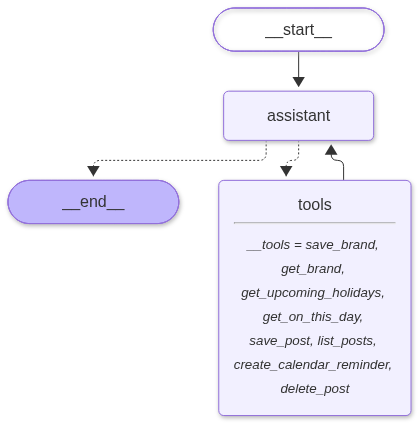

In [65]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:  # draw_mermaid_png uses an online service
    print("PNG failed:", e)
    print(graph.get_graph().draw_mermaid())

## 5. Tests

Helper functions:
- `use_thread(name)` – choose a conversation (`thread_id`). A new name = empty conversation memory.
- `chat(text)` / `answer(True/False)` – send a message / answer the approval question.
- Every call prints the **trajectory** of the turn with `m.pretty_print()` (all new messages: human, AI, tool calls, tool results) and the list of tools called.
- `record(...)` checks the result automatically and adds a row to the evaluation table.

In [66]:
import pandas as pd
from langchain_core.messages import ToolMessage

EVAL = []
config = None
seen = {}            # how many messages of each thread are already printed
last = {}            # info about the latest turn


def use_thread(name):
    """Switch to a conversation. A new thread_id means empty conversation memory."""
    global config
    config = {"configurable": {"thread_id": name}}
    seen.setdefault(name, 0)
    print("🧵 thread:", name)


def show(result):
    """Print the trajectory of the latest turn and return the names of the tools called."""
    tid = config["configurable"]["thread_id"]
    msgs = result["messages"]
    new = msgs[seen[tid]:]
    for m in new:
        m.pretty_print()
    seen[tid] = len(msgs)
    called = [tc["name"] for m in new for tc in (getattr(m, "tool_calls", None) or [])]
    last["called"] = called
    last["tool_results"] = [m.content for m in new if isinstance(m, ToolMessage)]
    last["interrupt"] = bool(result.get("__interrupt__"))
    last["reply"] = msgs[-1].content if msgs and msgs[-1].type == "ai" else ""
    print("\n🔧 Tools called:", called or "none")
    if last["interrupt"]:
        print("⏸ APPROVAL NEEDED:", result["__interrupt__"][0].value)
    return called


def chat(text):
    return show(graph.invoke({"messages": [HumanMessage(content=text)]}, config))


def answer(approved: bool):
    return show(graph.invoke(Command(resume=approved), config))


def posts_now():
    return read_json(POSTS_FILE, [])


def record(n, query, expected, passed, notes=""):
    EVAL.append({"#": n, "Query": query, "Expected": expected,
                 "Pass?": "✅" if passed else "❌", "Notes": notes})
    print(f"\nTest {n}:", "✅ PASS" if passed else "❌ FAIL", notes)


print("Test helpers ready")

Test helpers ready


### Test 1 – Save the brand from the brand book

In [67]:
use_thread("t1-brand")
q = ("აი ჩემი ბრენდბუქი და ბრენდ-პლატფორმა, დაიმახსოვრე: "
     "ტონი – მეგობრული, მოკლე წინადადებები. აუდიტორია – 18-25 წლის სტუდენტები თბილისში. "
     "ღირებულებები – შემოქმედებითობა და ხარისხი. ფერები – #1E3A8A, #F5F5F5. შრიფტი – Montserrat. "
     "აკრძალულია – სლენგი და კონკურენტების სახელები.")
called = chat(q)
record(1, "Brand book text", "save_brand called, brand.json saved",
       "save_brand" in called and read_json(BRAND_FILE, None) is not None)

🧵 thread: t1-brand
================================ Human Message =================================

აი ჩემი ბრენდბუქი და ბრენდ-პლატფორმა, დაიმახსოვრე: ტონი – მეგობრული, მოკლე წინადადებები. აუდიტორია – 18-25 წლის სტუდენტები თბილისში. ღირებულებები – შემოქმედებითობა და ხარისხი. ფერები – #1E3A8A, #F5F5F5. შრიფტი – Montserrat. აკრძალულია – სლენგი და კონკურენტების სახელები.
================================== Ai Message ==================================
Tool Calls:
  save_brand (fc_615c9421-57c0-4d7d-bdd2-03f80d7eb437)
 Call ID: fc_615c9421-57c0-4d7d-bdd2-03f80d7eb437
  Args:
    audience: 18-25 წლის სტუდენტები თბილისში
    colors: #1E3A8A, #F5F5F5
    fonts: Montserrat
    forbidden: სლენგი და კონკურენტების სახელები
    tone: მეგობრული, მოკლე წინადადებები
    values: შემოქმედებითობა და ხარისხი
================================= Tool Message =================================
Name: save_brand

Brand saved.
================================== Ai Message ==================================

მზად 

### Test 2 – New conversation: the brand is read from the file (memory between sessions)

In [68]:
use_thread("t2-plan")   # new thread: the agent does not see test 1
called = chat("რა იცი ჩემს ბრენდზე?")
record(2, "რა იცი ჩემს ბრენდზე? (new thread)", "get_brand reads the saved brand",
       "get_brand" in called and "Montserrat" in last["reply"])

🧵 thread: t2-plan
================================ Human Message =================================

რა იცი ჩემს ბრენდზე?
================================== Ai Message ==================================
Tool Calls:
  get_brand (fc_754b8d2b-fbf4-4531-a5db-03c8af4abd25)
 Call ID: fc_754b8d2b-fbf4-4531-a5db-03c8af4abd25
  Args:
================================= Tool Message =================================
Name: get_brand

{"tone": "მეგობრული, მოკლე წინადადებები", "audience": "18-25 წლის სტუდენტები თბილისში", "values": "შემოქმედებითობა და ხარისხი", "colors": "#1E3A8A, #F5F5F5", "fonts": "Montserrat", "forbidden": "სლენგი და კონკურენტების სახელები"}
================================== Ai Message ==================================

თქვენი ბრენდი შემდეგი ძირითადი ელემენტებითაა განსაზღვრული:

- **ტონი** – მეგობრული, მოკლე წინადადებები.  
- **მიზნობარი** – 18‑დან 25 წლამდე ასაკის სტუდენტები, რომლებიც ცხოვრობენ თბილისში.  
- **ღირებულებები** – შემოქმედებითობა და ხარისხი.  
- **ფერები** – #1E3A8A

### Test 3 – Post idea request: date review and question

In [69]:
called = chat("პოსტის იდეა მჭირდება")
ok = called[:1] == ["get_brand"] and "get_upcoming_holidays" in called
record(3, "პოსტის იდეა მჭირდება", "get_brand → get_upcoming_holidays → date review + question",
       ok, f"tools: {called}")

================================ Human Message =================================

პოსტის იდეა მჭირდება
================================== Ai Message ==================================
Tool Calls:
  get_upcoming_holidays (fc_b370e515-2fbb-428a-b39d-fff19240ebb9)
 Call ID: fc_b370e515-2fbb-428a-b39d-fff19240ebb9
  Args:
    days: 30
================================= Tool Message =================================
Name: get_upcoming_holidays

[{"date": "2026-11-23", "name": "Saint George's Day", "local_name": "გიორგობა", "days_left": 1}]
================================== Ai Message ==================================

მომავალ 30 დღეში ერთ-ერთი მნიშვნელოვანი დღესასწაულია:

- **23 ნოემბერი – გიორგობა (Saint George's Day)** – 1 დღე დარჩენილია.

გსურთ, თქვენი პოსტის იდეა იყოს დაკავშირებული გიორგობის თემასთან, თუ გინდათ, რომ შემოგთავაზოთ იდეა ბრენდის ღირებულებების (შემოქმედებითობა, ხარისხი) საფუძველზე, დამოუკიდებლად დღესასწაულისგან?

🔧 Tools called: ['get_upcoming_holidays']

Test 3: ❌ FAIL too

### Test 4 – The user chooses a date: idea, caption, hashtags, visual brief (conversation memory)

In [70]:
called = chat("კი, უახლოეს თარიღს დაუკავშირე. ამ დღის საინტერესო ისტორიული ფაქტიც შეამოწმე.")
reply = last["reply"]
record(4, "კი, უახლოეს თარიღს დაუკავშირე…", "idea + caption + hashtags + visual brief for the chosen date",
       "#" in reply and len(reply) > 300,
       f"get_on_this_day called: {'get_on_this_day' in called}")

================================ Human Message =================================

კი, უახლოეს თარიღს დაუკავშირე. ამ დღის საინტერესო ისტორიული ფაქტიც შეამოწმე.
================================== Ai Message ==================================
Tool Calls:
  get_on_this_day (fc_1ded518e-19a9-4b79-9580-668fc581ace4)
 Call ID: fc_1ded518e-19a9-4b79-9580-668fc581ace4
  Args:
    day: 23
    month: 11
================================= Tool Message =================================
Name: get_on_this_day

[{"fact": "2015: Blue Origin's New Shepard space vehicle became the first rocket to successfully fly to space and then return to Earth for a controlled, vertical landing."}, {"fact": "2002: Space Shuttle Endeavour launches on STS-113 to the International Space Station carrying the Expedition 6 crew and the P1 truss."}, {"fact": "1992: The first smartphone, the IBM Simon, is introduced at COMDEX in Las Vegas, Nevada."}, {"fact": "1976: Jacques Mayol is the first man to reach a depth of 100 m (330

### Test 5 – Final materials: the post is saved

In [71]:
before = len(posts_now())
called = chat("საბოლოო ქოფი: „გილოცავთ! შექმენით და გაიხარეთ.“ ვიზუალი: https://drive.google.com/test. "
              "პოსტი გამოქვეყნდეს ამ დღესასწაულის დღეს, 12:00 საათზე.")
after = posts_now()
record(5, "Final caption + link + time", "save_post, one new post in posts.json",
       "save_post" in called and len(after) == before + 1)
POST_ID = max(p["id"] for p in after) if after else None
print("POST_ID:", POST_ID, after[-1] if after else "")

================================ Human Message =================================

საბოლოო ქოფი: „გილოცავთ! შექმენით და გაიხარეთ.“ ვიზუალი: https://drive.google.com/test. პოსტი გამოქვეყნდეს ამ დღესასწაულის დღეს, 12:00 საათზე.
================================== Ai Message ==================================
Tool Calls:
  save_post (fc_0a6bb674-6b48-4e52-9797-780b7340d71d)
 Call ID: fc_0a6bb674-6b48-4e52-9797-780b7340d71d
  Args:
    caption: გილოცავთ! შექმენით და გაიხარეთ.
    hashtags: #გიორგობა #ინოვაცია #BlueOrigin #NewShepard #შემოქმედებითობა #ხარისხი #სტუდენტები #თბილისი
    idea: გიორგობის დღეს, 23 ნოემბერი, ვიხსენებთ 2015‑ის Blue Origin-ის New Shepard-ის წარმატებულ ბრუნვას, როგორც ინოვაციის სიმბოლოს, რომელიც ასახავს ბრენდის შემოქმედებითობასა და ხარისხს.
    material_links: https://drive.google.com/test
    publish_date: 2026-11-23
    publish_time: 12:00
    visual_brief: ფორმატი: Reel (15‑30 წმ) + Story (2 ფრეიმი). კომპოზიცია: ფერადი გეორგიის მთის ფონზე ლურჯი #1E3A8A, გადამრთველი 

### Test 6 – Conversation memory: same thread remembers, a new thread does not

In [72]:
chat("რა საათზე ქვეყნდება ჩვენი პოსტი?")
same_ok = "12:00" in last["reply"]

use_thread("t6-other")
chat("ამ საუბარში რა გკითხე პირველად?")
other_ok = "პოსტის იდეა" not in last["reply"]

use_thread("t2-plan")   # back to the main conversation
record(6, "Same thread vs new thread", "same thread knows 12:00; new thread knows nothing",
       same_ok and other_ok, f"same thread: {same_ok}, new thread: {other_ok}")

================================ Human Message =================================

რა საათზე ქვეყნდება ჩვენი პოსტი?
================================== Ai Message ==================================

თქვენი პოსტი 23 ნოემბერში, 12:00 საათზე (შუადღის) გამოქვეყნდება.

🔧 Tools called: none
🧵 thread: t6-other
================================ Human Message =================================

ამ საუბარში რა გკითხე პირველად?
================================== Ai Message ==================================

ამ საუბარში მე ჯერ არაფერი გკითხე – თქვენ პირველად დამიკავშირდით.

🔧 Tools called: none
🧵 thread: t2-plan

Test 6: ✅ PASS same thread: True, new thread: True


### Test 7 – Destructive action APPROVED: create a Google Calendar event

In [73]:
chat("შექმენი Google Calendar-ის შეხსენება ამ პოსტისთვის")
asked_7 = last["interrupt"]

================================ Human Message =================================

შექმენი Google Calendar-ის შეხსენება ამ პოსტისთვის
================================== Ai Message ==================================
Tool Calls:
  create_calendar_reminder (fc_446bc3a9-9308-4142-9ee1-f04f8f6f0daa)
 Call ID: fc_446bc3a9-9308-4142-9ee1-f04f8f6f0daa
  Args:
    post_id: 1

🔧 Tools called: ['create_calendar_reminder']
⏸ APPROVAL NEEDED: Google Calendar-ში ვქმნი შეხსენებას: პოსტი #1, 2026-11-23 12:00. ვადასტურებ?


In [74]:
if asked_7:
    answer(True)   # ✅ user approves
post = next((p for p in posts_now() if p["id"] == POST_ID), {})
print("event_id saved:", post.get("event_id"))
record(7, "Calendar reminder → YES", "approval question, then event created in Google Calendar",
       asked_7 and bool(post.get("event_id")))

================================= Tool Message =================================
Name: create_calendar_reminder

Event created in Google Calendar on 2026-11-23 12:00.
================================== Ai Message ==================================

Google Calendar-ში შეხსენება შექმნილია: 23 ნოემბერი 2026, 12:00. წარმატებული პოსტის გამოქვეყნება!

🔧 Tools called: none
event_id saved: bu7244gc6sb43bva9pesq6n3i8@google.com

Test 7: ✅ PASS 


### Test 8 – Destructive action DENIED: delete the post → nothing changes

In [75]:
chat("წაშალე ეს პოსტი")
asked_8 = last["interrupt"]

================================ Human Message =================================

წაშალე ეს პოსტი
================================== Ai Message ==================================
Tool Calls:
  delete_post (fc_486119c6-36eb-499c-9906-225340523c5d)
 Call ID: fc_486119c6-36eb-499c-9906-225340523c5d
  Args:
    post_id: 1

🔧 Tools called: ['delete_post']
⏸ APPROVAL NEEDED: ვშლი პოსტს #1: „გიორგობის დღეს, 23 ნოემბერი, ვიხსენებთ 2015‑ის Blue Origin-ი“, 2026-11-23 12:00 და მის მოვლენას Google Calendar-ში. ვადასტურებ?


In [76]:
before = posts_now()
if asked_8:
    answer(False)  # ❌ user denies
after = posts_now()
print("Data unchanged:", before == after)
record(8, "Delete post → NO", "approval question, posts.json unchanged",
       asked_8 and before == after and any(p["id"] == POST_ID for p in after))

================================= Tool Message =================================
Name: delete_post

User denied. Post #1 was NOT deleted. Nothing changed.
================================== Ai Message ==================================

მომხმარებელმა უარყოფა გამოაცხადა, ამიტომ პოსტი #1 არ წაიშალა და ყველაფერი unchanged დარჩება. თუ გსურთ სხვა მოქმედება, შეგვატყობინეთ.

🔧 Tools called: none
Data unchanged: True

Test 8: ✅ PASS 


### Test 9 – Destructive action APPROVED: delete the post and its Calendar event

In [77]:
chat("გადავიფიქრე, წაშალე ეს პოსტი")
asked_9 = last["interrupt"]

================================ Human Message =================================

გადავიფიქრე, წაშალე ეს პოსტი
================================== Ai Message ==================================
Tool Calls:
  delete_post (fc_860b37b6-d3dc-4436-85c0-2ea48a9100dd)
 Call ID: fc_860b37b6-d3dc-4436-85c0-2ea48a9100dd
  Args:
    post_id: 1

🔧 Tools called: ['delete_post']
⏸ APPROVAL NEEDED: ვშლი პოსტს #1: „გიორგობის დღეს, 23 ნოემბერი, ვიხსენებთ 2015‑ის Blue Origin-ი“, 2026-11-23 12:00 და მის მოვლენას Google Calendar-ში. ვადასტურებ?


In [78]:
if asked_9:
    answer(True)   # ✅ user approves
deleted = not any(p["id"] == POST_ID for p in posts_now())
cal_ok = any("Google Calendar event deleted" in t for t in last.get("tool_results", []))
record(9, "Delete post → YES", "post and its Calendar event deleted",
       asked_9 and deleted and cal_ok, f"calendar event deleted: {cal_ok}")

================================= Tool Message =================================
Name: delete_post

Post #1 deleted from the content plan. Google Calendar event deleted.
================================== Ai Message ==================================

პოსტი #1 წარმატებით წაიშალა, ასევე მისი Google Calendar‑ის შეხსენება წაიშალა. თუ გჭირდებათ ახალი პოსტის შექმნა ან სხვა დახმარება, გთხოვთ, შეგვატყობინეთ.

🔧 Tools called: none

Test 9: ✅ PASS calendar event deleted: True


### Test 10 – Delete a post that does not exist

In [79]:
before = posts_now()
chat("წაშალე პოსტი #999")
record(10, "წაშალე პოსტი #999", "'not found', no approval question, nothing changed",
       not last["interrupt"] and posts_now() == before)

================================ Human Message =================================

წაშალე პოსტი #999
================================== Ai Message ==================================
Tool Calls:
  delete_post (fc_903f8d72-04f3-45df-b078-d09a6e8dbf2a)
 Call ID: fc_903f8d72-04f3-45df-b078-d09a6e8dbf2a
  Args:
    post_id: 999
================================= Tool Message =================================
Name: delete_post

Post #999 not found.
================================== Ai Message ==================================

პოსტი #999 ვერ მოიძებნა. თუ გაქვთ სხვა მოთხოვნა, გთხოვთ, მოგვაწოდოთ.

🔧 Tools called: ['delete_post']

Test 10: ✅ PASS 


## 6. Evaluation

Automatic results of this run:

In [80]:
df = pd.DataFrame(EVAL)
print(f"Passed: {(df['Pass?'] == '✅').sum()} / {len(df)}")
df

Passed: 9 / 10


,#,Query,Expected,Pass?,Notes
0,1,Brand book text,"save_brand called, brand.json saved",✅,
1,2,რა იცი ჩემს ბრენდზე? (new thread),get_brand reads the saved brand,✅,
2,3,პოსტის იდეა მჭირდება,get_brand → get_upcoming_holidays → date revie...,❌,tools: ['get_upcoming_holidays']
3,4,"კი, უახლოეს თარიღს დაუკავშირე…",idea + caption + hashtags + visual brief for t...,✅,get_on_this_day called: True
4,5,Final caption + link + time,"save_post, one new post in posts.json",✅,
5,6,Same thread vs new thread,same thread knows 12:00; new thread knows nothing,✅,"same thread: True, new thread: True"
6,7,Calendar reminder → YES,"approval question, then event created in Googl...",✅,
7,8,Delete post → NO,"approval question, posts.json unchanged",✅,
8,9,Delete post → YES,post and its Calendar event deleted,✅,calendar event deleted: True
9,10,წაშალე პოსტი #999,"'not found', no approval question, nothing cha...",✅,


### Evaluation table

Results of the last **Run all** (22 Nov 2026), after fixing the prompt and the Wikipedia filter. Automatic check: **9 / 10 passed**, plus 1 partial pass on manual review.

| # | Query | Expected | Pass? | Notes |
|---|---|---|---|---|
| 1 | Brand book text | `save_brand` called, `brand.json` saved | ✅ | All 6 brand fields were extracted correctly. |
| 2 | "რა იცი ჩემს ბრენდზე?" (new thread) | `get_brand` reads the saved brand | ✅ | The brand came from the Drive file, not from the conversation. Colour names are now correct (#1E3A8A dark blue, #F5F5F5 white). |
| 3 | "პოსტის იდეა მჭირდება" | `get_brand` → `get_upcoming_holidays` → date review + question | ⚠️ partial | Holiday review and question were correct, but `get_brand` was skipped: the brand was already in this conversation from test 2. The automatic check marks it ❌. |
| 4 | "კი, უახლოეს თარიღს დაუკავშირე…" | idea + caption + hashtags + visual brief | ✅ | It called `get_on_this_day` and wrote the full idea without another question. The year (2015) was copied correctly. The filter returned only neutral events (space, technology, records). Weak point: some Georgian sentences in the idea are unclear and need editing. |
| 5 | Final caption + link + time | `save_post`, one new post | ✅ | The date (2026-11-23) was taken correctly from the holiday. |
| 6 | Same thread vs new thread | same thread remembers 12:00, new thread does not | ✅ | Conversation memory and thread isolation both work. |
| 7 | Calendar reminder → YES | approval question, event created | ✅ | A real Google Calendar event was created and its `event_id` was saved. |
| 8 | Delete post → NO | approval question, data unchanged | ✅ | `posts.json` stayed the same. The reply contains one English word ("unchanged"). |
| 9 | Delete post → YES | post and Calendar event deleted | ✅ | The post and the Calendar event were both deleted. |
| 10 | "წაშალე პოსტი #999" | "not found", no approval question | ✅ | No approval question, nothing changed. |

**What changed after the first run** (first run: 8 / 10):
- **Prompt:** when the user has already chosen a date, the agent must write the full idea and must not ask again. Test 4 now passes.
- **Facts:** `get_on_this_day` returns each event as `"YEAR: text"`, and the prompt says to copy the year exactly. In the first run the year was wrong (2015 → 2022); now it is correct.
- **Wikipedia filter:** an event is kept only if it has a positive word and no negative word. In the first run a scandal and political events got through; now they are removed.

**Observations:**
- **Approval flow is reliable:** tests 7–10 passed in both runs.
- **Test 3:** the model skips `get_brand` when the brand is already in the conversation. The answer is still correct, but the rule "ALWAYS call get_brand first" is not always followed.
- **Georgian language quality** is the main weakness: some sentences are unclear, words are invented, and English words appear. Captions must be checked by a person before publishing.
- **Non-deterministic:** results can change between runs; the keyword filter can still miss some unsuitable events or remove good ones.

## 7. Project files for GitHub

The cells below delete the old files and create new ones in the Colab Files panel (`/content`):
`agent.py`, `app.py`, `main.py`, `requirements.txt`, `apps_script.gs`, `.env.example`, `.gitignore`, `README.md`.
These cells do not need the API keys. Download the files (or `github_files.zip`) from the Files panel,
and download this notebook with **File → Download → Download .ipynb**, renamed to `agent.ipynb`.

In [81]:
%cd /content
!rm -f agent.py app.py main.py requirements.txt apps_script.gs .env.example .gitignore README.md github_files.zip
!rm -rf __pycache__
print("Old files deleted")

/content
Old files deleted


In [82]:
%%writefile agent.py
"""Content Planner Agent: shared agent code used by app.py (Streamlit) and main.py (CLI).

Secrets are read from environment variables (never hard-code them):
    GROQ_API_KEY    - Groq API key
    CALENDAR_URL    - Google Apps Script web app URL (ends with /exec)
    CALENDAR_TOKEN  - the SECRET value from apps_script.gs
Optional:
    DATA_DIR        - folder for brand.json and posts.json (default: ./data)
    GROQ_MODEL      - Groq model id (default: openai/gpt-oss-120b)
"""

import json
import os
from datetime import date, datetime, timedelta
from typing import Annotated

import requests
from typing_extensions import TypedDict
from langchain_core.messages import SystemMessage
from langchain_core.tools import tool
from langchain_groq import ChatGroq
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.types import interrupt

# ---------- Storage (brand and posts survive between sessions) ----------

DATA_DIR = os.environ.get("DATA_DIR", os.path.join(os.path.dirname(os.path.abspath(__file__)), "data"))
os.makedirs(DATA_DIR, exist_ok=True)
BRAND_FILE = os.path.join(DATA_DIR, "brand.json")
POSTS_FILE = os.path.join(DATA_DIR, "posts.json")


def read_json(path, default):
    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            return json.load(f)
    return default


def write_json(path, data):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=2)


# ---------- Tools: brand ----------

@tool
def save_brand(tone: str, audience: str, values: str, colors: str, fonts: str, forbidden: str) -> str:
    """Save the brand profile extracted from the brand book and brand platform.
    Use when the user shares brand book or brand platform text.
    tone: voice and tone; audience: target audience; values: brand values;
    colors: brand colors (names or HEX); fonts: brand fonts;
    forbidden: what the brand must never say or do."""
    brand = {"tone": tone, "audience": audience, "values": values,
             "colors": colors, "fonts": fonts, "forbidden": forbidden}
    write_json(BRAND_FILE, brand)
    return "Brand saved."


@tool
def get_brand() -> dict:
    """Read the saved brand profile. Always call this before writing a post idea."""
    brand = read_json(BRAND_FILE, None)
    if brand is None:
        return {"error": "No brand saved yet. Ask the user for the brand book."}
    return brand


# ---------- Tools: external APIs ----------

@tool
def get_upcoming_holidays(days: int = 30) -> list:
    """Get public holidays in Georgia (the country) within the next `days` days (Nager.Date API).
    Returns a list of {date, name, local_name, days_left}. An empty list means no holidays in that period."""
    today = date.today()
    end = today + timedelta(days=days)
    result = []
    for year in sorted({today.year, end.year}):
        try:
            r = requests.get(f"https://date.nager.at/api/v3/PublicHolidays/{year}/GE", timeout=20)
        except requests.RequestException as e:
            return [{"error": f"Nager.Date is not reachable: {e}"}]
        if r.status_code != 200 or not r.text.strip():
            return [{"error": f"Nager.Date returned status {r.status_code} for Georgia ({year})"}]
        for h in r.json():
            d = date.fromisoformat(h["date"])
            if today <= d <= end:
                result.append({"date": h["date"], "name": h["name"],
                               "local_name": h["localName"], "days_left": (d - today).days})
    return result


WIKI_HEADERS = {"User-Agent": "ContentPlannerAgent/0.1 (BTU student project)"}

# An event is kept only if it has a positive word AND no negative word,
# so wars, disasters, scandals and politics do not reach a brand post
POSITIVE_WORDS = ("first", "launch", "invent", "discover", "found", "open", "premiere",
                  "record", "award", "prize", "publish", "release", "complete")
NEGATIVE_WORDS = ("kill", "dead", "death", "dies", "die ", "war", "attack", "bomb", "terror",
                  "earthquake", "fire", "massacre", "murder", "crash", "shoot", "invade",
                  "invasion", "riot", "disaster", "execut", "assassin", "genocide", "explosion",
                  "scandal", "offensive", "apolog", "protest", "coup", "impeach", "trial",
                  "arrest", "sink", "crisis", "president", "elect", "government", "revolution")


@tool
def get_on_this_day(month: int, day: int) -> list:
    """Get up to 5 positive or neutral historical events for this month and day (Wikipedia 'On this day').
    Each item is {"fact": "YEAR: text"}; copy the year exactly as given.
    Wars, disasters, crimes, scandals and politics are filtered out.
    month: 1-12, day: 1-31. Call only for holiday dates or dates the user chose."""
    urls = [
        f"https://en.wikipedia.org/api/rest_v1/feed/onthisday/events/{month:02d}/{day:02d}",
        f"https://api.wikimedia.org/feed/v1/wikipedia/en/onthisday/events/{month:02d}/{day:02d}",
    ]
    for url in urls:
        try:
            r = requests.get(url, headers=WIKI_HEADERS, timeout=20)
        except requests.RequestException:
            continue
        if r.status_code == 200:
            events = r.json().get("events", [])
            safe = []
            for e in events:
                text = (e.get("text") or "").lower()
                if any(p in text for p in POSITIVE_WORDS) and not any(n in text for n in NEGATIVE_WORDS):
                    safe.append({"fact": f'{e.get("year")}: {e.get("text")}'})
            if not safe:
                return [{"info": "No suitable (positive or neutral) events for this date."}]
            return safe[:5]
    return [{"error": "Wikipedia 'On this day' is not reachable"}]


# ---------- Tools: posts ----------

@tool
def save_post(idea: str, caption: str, hashtags: str, visual_brief: str,
              material_links: str, publish_date: str, publish_time: str) -> str:
    """Save a planned post to the content plan.
    publish_date format YYYY-MM-DD, publish_time format HH:MM (24h).
    material_links: links to the final visuals (e.g. Google Drive).
    Call only when the user gave the final caption, material link, date and time."""
    try:
        datetime.strptime(f"{publish_date} {publish_time}", "%Y-%m-%d %H:%M")
    except ValueError:
        return "Not saved: publish_date must be YYYY-MM-DD and publish_time must be HH:MM."
    posts = read_json(POSTS_FILE, [])
    post_id = max([p["id"] for p in posts], default=0) + 1
    posts.append({"id": post_id, "idea": idea, "caption": caption, "hashtags": hashtags,
                  "visual_brief": visual_brief, "material_links": material_links,
                  "publish_date": publish_date, "publish_time": publish_time})
    write_json(POSTS_FILE, posts)
    return f"Post #{post_id} saved for {publish_date} {publish_time}."


@tool
def list_posts() -> list:
    """Show all planned posts (the content plan), sorted by date. Use it to find a post number."""
    posts = read_json(POSTS_FILE, [])
    return sorted(posts, key=lambda p: (p["publish_date"], p["publish_time"]))


# ---------- Tools with approval: Google Calendar ----------

def calendar_call(payload: dict) -> dict:
    """Send a request to the Google Apps Script web app that creates and deletes Calendar events."""
    url = os.environ.get("CALENDAR_URL")
    token = os.environ.get("CALENDAR_TOKEN")
    if not url or not token:
        return {"error": "CALENDAR_URL or CALENDAR_TOKEN is not set"}
    try:
        r = requests.post(url, json={**payload, "token": token}, timeout=30)
        return r.json()
    except (requests.RequestException, ValueError) as e:
        return {"error": f"Calendar web app did not answer correctly: {e}"}


@tool
def create_calendar_reminder(post_id: int) -> str:
    """Create a Google Calendar event for a saved post, with caption, hashtags,
    material links and visual brief in the description. Asks the user for approval first."""
    posts = read_json(POSTS_FILE, [])
    post = next((p for p in posts if p["id"] == post_id), None)
    if post is None:
        return f"Post #{post_id} not found."
    approved = interrupt(
        f'Google Calendar-ში ვქმნი შეხსენებას: პოსტი #{post_id}, '
        f'{post["publish_date"]} {post["publish_time"]}. ვადასტურებ?')
    if not approved:
        return "User denied. Reminder was NOT created. The post stays saved."
    start = datetime.strptime(f'{post["publish_date"]} {post["publish_time"]}', "%Y-%m-%d %H:%M")
    end = start + timedelta(minutes=30)
    result = calendar_call({
        "action": "create",
        "title": f'Publish post #{post_id}: {post["idea"][:60]}',
        "start": start.strftime("%Y-%m-%dT%H:%M:00+04:00"),
        "end": end.strftime("%Y-%m-%dT%H:%M:00+04:00"),
        "description": (f'Caption:\n{post["caption"]}\n\nHashtags: {post["hashtags"]}\n\n'
                        f'Materials: {post["material_links"]}\n\nVisual brief: {post["visual_brief"]}'),
    })
    if not result.get("ok"):
        return f"Calendar error: {result}"
    post["event_id"] = result["id"]
    write_json(POSTS_FILE, posts)
    return f'Event created in Google Calendar on {post["publish_date"]} {post["publish_time"]}.'


@tool
def delete_post(post_id: int) -> str:
    """Delete a planned post from the content plan AND its Google Calendar event, if one was created.
    Asks the user for approval first."""
    posts = read_json(POSTS_FILE, [])
    post = next((p for p in posts if p["id"] == post_id), None)
    if post is None:
        return f"Post #{post_id} not found."
    approved = interrupt(
        f'ვშლი პოსტს #{post_id}: „{post["idea"][:60]}“, '
        f'{post["publish_date"]} {post["publish_time"]}'
        f'{" და მის მოვლენას Google Calendar-ში" if post.get("event_id") else ""}. ვადასტურებ?')
    if not approved:
        return f"User denied. Post #{post_id} was NOT deleted. Nothing changed."
    calendar_msg = "No Google Calendar event was linked to this post."
    if post.get("event_id"):
        result = calendar_call({"action": "delete", "id": post["event_id"]})
        calendar_msg = ("Google Calendar event deleted." if result.get("ok")
                        else f"Google Calendar event NOT deleted: {result}")
    write_json(POSTS_FILE, [p for p in posts if p["id"] != post_id])
    return f"Post #{post_id} deleted from the content plan. {calendar_msg}"


TOOLS = [save_brand, get_brand, get_upcoming_holidays, get_on_this_day,
         save_post, list_posts, create_calendar_reminder, delete_post]

# ---------- Agent ----------

SYSTEM_PROMPT = """You are Content Planner Agent. You help a brand plan social media posts.
Always reply in the user's language (usually Georgian). Write correct literary Georgian.
Use only Georgian letters in Georgian sentences: never insert Armenian, Cyrillic or other similar-looking letters,
and never insert words from other languages (brand names, HEX codes, fonts and hashtags are allowed).

When the user shares a brand book or brand platform, extract the fields and call save_brand.

When the user asks for a post idea:
1. ALWAYS call get_brand first. You do not know the brand until you call it.
   Never say that the brand is missing unless get_brand returned an error.
2. Call get_upcoming_holidays with days=30.
3. If holidays are coming, you may call get_on_this_day for those holiday dates
   and use only the events it returns.
4. Give a short review of the upcoming dates and ASK whether to connect the idea to one of them.
   Do not write the idea before the user answers.
   When the user has chosen a date or said yes, do NOT ask any more questions:
   write the full idea (idea, caption, hashtags, visual brief) in the same reply.
5. If no holiday is coming, skip the question and build the idea on the brand only.
6. The idea must include: the idea, a caption draft, hashtags, and a visual brief
   (format: post/story/Reels, composition, brand colors, text on the visual, mood).
   Follow the brand tone and never break the brand's "forbidden" rules.

Call save_post only when the user gives the final caption, material link, date and time.
To find a post number, use the conversation or call list_posts.

Approval: create_calendar_reminder and delete_post ask the user for approval by themselves.
When the user asks to create a reminder or delete a post, call the tool directly; do not ask for confirmation in text first.
If the tool says the user denied, tell the user that nothing was changed and do not ask again.

Facts: when you mention a historical event, copy its year exactly from get_on_this_day.
Never change a year or a date. Use only facts and dates from tool results. Never invent dates or events."""



class State(TypedDict):
    messages: Annotated[list, add_messages]


def build_graph(model: str | None = None):
    """Build and compile the agent graph with in-memory conversation memory."""
    llm = ChatGroq(
        model=model or os.environ.get("GROQ_MODEL", "openai/gpt-oss-120b"),
        temperature=0.3,
        max_tokens=2000,
    )
    llm_with_tools = llm.bind_tools(TOOLS)

    def assistant(state: State):
        messages = [SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
        return {"messages": [llm_with_tools.invoke(messages)]}

    builder = StateGraph(State)
    builder.add_node("assistant", assistant)
    builder.add_node("tools", ToolNode(TOOLS))
    builder.add_edge(START, "assistant")
    builder.add_conditional_edges("assistant", tools_condition)
    builder.add_edge("tools", "assistant")
    return builder.compile(checkpointer=InMemorySaver())

Writing agent.py


In [83]:
%%writefile app.py
"""Content Planner Agent - Streamlit chat page.

Run:  streamlit run app.py
Secrets: put GROQ_API_KEY, CALENDAR_URL, CALENDAR_TOKEN in .streamlit/secrets.toml
(or in environment variables). Never commit that file.
"""

import os
import uuid

import streamlit as st
from langgraph.types import Command

# Copy Streamlit secrets into environment variables before the agent is built
try:
    for key in ("GROQ_API_KEY", "CALENDAR_URL", "CALENDAR_TOKEN", "GROQ_MODEL"):
        if key in st.secrets:
            os.environ[key] = st.secrets[key]
except Exception:
    pass  # no secrets.toml: use environment variables

from agent import build_graph, list_posts  # noqa: E402

st.set_page_config(page_title="Content Planner Agent", page_icon="🗓️")
st.title("🗓️ Content Planner Agent")
st.caption("Post ideas from your brand and upcoming Georgian holidays, "
           "saved to Google Calendar after your approval.")

if not os.environ.get("GROQ_API_KEY"):
    st.error("GROQ_API_KEY is not set. Add it to .streamlit/secrets.toml.")
    st.stop()

# One graph and one conversation (thread_id) per browser session
if "graph" not in st.session_state:
    st.session_state.graph = build_graph()
    st.session_state.config = {"configurable": {"thread_id": str(uuid.uuid4())}}
    st.session_state.chat = []          # list of (role, text) for display
    st.session_state.pending = None     # approval question, if the agent stopped

graph = st.session_state.graph
config = st.session_state.config


def handle(result):
    """Show the agent reply or remember the approval question."""
    if result.get("__interrupt__"):
        st.session_state.pending = result["__interrupt__"][0].value
    else:
        st.session_state.pending = None
        reply = result["messages"][-1].content
        if reply:
            st.session_state.chat.append(("assistant", reply))


def run(payload, spinner_text):
    try:
        with st.spinner(spinner_text):
            handle(graph.invoke(payload, config))
    except Exception as e:  # e.g. Groq rate limit (429)
        st.session_state.chat.append(("assistant", f"⚠️ Error: {e}"))


with st.sidebar:
    st.subheader("Planned posts")
    posts = list_posts.invoke({})
    if not posts:
        st.write("No posts yet.")
    for p in posts:
        mark = " 📅" if p.get("event_id") else ""
        st.write(f'#{p["id"]} · {p["publish_date"]} {p["publish_time"]}{mark}  \n{p["idea"][:50]}')
    if st.button("New conversation"):
        for k in ("graph", "config", "chat", "pending"):
            st.session_state.pop(k, None)
        st.rerun()

for role, text in st.session_state.chat:
    with st.chat_message(role):
        st.markdown(text)

# Approval flow: the agent stopped before a calendar / delete action
if st.session_state.pending:
    with st.chat_message("assistant"):
        st.warning(f"⏸ {st.session_state.pending}")
        col1, col2 = st.columns(2)
        if col1.button("✅ კი, ვადასტურებ"):
            st.session_state.chat.append(("user", "✅ კი"))
            run(Command(resume=True), "Working...")
            st.rerun()
        if col2.button("❌ არა"):
            st.session_state.chat.append(("user", "❌ არა"))
            run(Command(resume=False), "Working...")
            st.rerun()

prompt = st.chat_input("მაგ.: პოსტის იდეა მჭირდება", disabled=bool(st.session_state.pending))
if prompt:
    st.session_state.chat.append(("user", prompt))
    run({"messages": [("user", prompt)]}, "Thinking...")
    st.rerun()

Writing app.py


In [84]:
%%writefile main.py
"""Content Planner Agent - terminal (CLI) version.

Run:  python main.py
Type 'exit' to quit.
"""

import os
import uuid

from langgraph.types import Command


def load_dotenv_file(path=".env"):
    """Load KEY=value lines from a local .env file (if it exists) into environment variables."""
    if not os.path.exists(path):
        return
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line and not line.startswith("#") and "=" in line:
                key, value = line.split("=", 1)
                os.environ.setdefault(key.strip(), value.strip().strip('"'))


def print_reply(result):
    last = result["messages"][-1]
    if getattr(last, "content", ""):
        print(f"\nAgent: {last.content}\n")


def main():
    load_dotenv_file()  # must run before the agent reads the environment
    if not os.environ.get("GROQ_API_KEY"):
        print("GROQ_API_KEY is not set. Add it to .env or your environment.")
        return

    from agent import build_graph

    graph = build_graph()
    config = {"configurable": {"thread_id": str(uuid.uuid4())}}
    print("Content Planner Agent. Type 'exit' to quit.\n")

    while True:
        try:
            text = input("You: ").strip()
        except (EOFError, KeyboardInterrupt):
            break
        if text.lower() in {"exit", "quit"}:
            break
        if not text:
            continue
        try:
            result = graph.invoke({"messages": [("user", text)]}, config)
            # Approval flow: the agent stops before calendar / delete actions
            while result.get("__interrupt__"):
                question = result["__interrupt__"][0].value
                answer = input(f"\n⏸ {question} (yes/no): ").strip().lower()
                approved = answer in {"yes", "y", "კი", "ki"}
                result = graph.invoke(Command(resume=approved), config)
            print_reply(result)
        except Exception as e:  # e.g. Groq rate limit (429)
            print(f"\n⚠️ Error: {e}\n")


if __name__ == "__main__":
    main()

Writing main.py


In [85]:
# requirements.txt: one library per line; versions are taken from this Colab session when installed
import importlib.metadata as md

lines = []
for pkg in ("langgraph", "langchain-core", "langchain-groq", "requests", "streamlit"):
    try:
        lines.append(f"{pkg}>={md.version(pkg)}")
    except md.PackageNotFoundError:
        lines.append(pkg)

with open("requirements.txt", "w") as f:
    f.write("\n".join(lines) + "\n")
print(open("requirements.txt").read())

langgraph>=1.2.19
langchain-core>=1.8.4
langchain-groq>=1.2.1
requests>=2.32.4
streamlit



In [86]:
%%writefile apps_script.gs
// Google Apps Script web app that creates and deletes Google Calendar events
// for Content Planner Agent.
// Setup: script.google.com -> New project -> paste this code -> change SECRET ->
// Deploy -> New deployment -> Web app (Execute as: Me, Who has access: Anyone).
// Never commit your real SECRET.

const SECRET = "CHANGE-ME";

function out(obj) {
  return ContentService.createTextOutput(JSON.stringify(obj))
    .setMimeType(ContentService.MimeType.JSON);
}

function doPost(e) {
  const data = JSON.parse(e.postData.contents);
  if (data.token !== SECRET) return out({error: "unauthorized"});
  const cal = CalendarApp.getDefaultCalendar();

  if (data.action === "delete") {
    const ev = cal.getEventById(data.id);
    if (!ev) return out({error: "event not found"});
    ev.deleteEvent();
    return out({ok: true});
  }

  const event = cal.createEvent(
    data.title, new Date(data.start), new Date(data.end),
    {description: data.description}
  );
  event.addPopupReminder(30);
  return out({ok: true, id: event.getId()});
}

Writing apps_script.gs


In [87]:
%%writefile .env.example
GROQ_API_KEY=
CALENDAR_URL=
CALENDAR_TOKEN=
# Optional
# GROQ_MODEL=openai/gpt-oss-120b
# DATA_DIR=./data

Writing .env.example


In [88]:
%%writefile .gitignore
# Secrets
.env
.streamlit/secrets.toml

# Local data (brand and posts)
data/

# Python / Jupyter
__pycache__/
*.pyc
.ipynb_checkpoints/

# Archive made in Colab
github_files.zip

Writing .gitignore


In [89]:
%%writefile README.md
# 🗓️ Content Planner Agent

**Content Planner Agent** helps a brand plan social media posts from idea to calendar reminder.

The user shares the brand book and brand platform once; the agent saves them (`brand.json`) and remembers them in every session. When asked for a post idea, it checks upcoming public holidays in Georgia (Nager.Date API) and suitable historical events for those dates (Wikipedia "On this day"), gives a short review and asks whether to connect the idea to one of the dates. If no holiday is coming, it builds the idea on the brand alone. It then writes the content idea, a caption draft, hashtags and a visual brief for the designer. The user gives the final caption, visual link, date and time; the agent saves the post and, **only after the user's approval**, creates a Google Calendar event with all the materials. Deleting a post also needs approval.

**Who it helps:** social media managers, small business owners and content creators who find it hard to plan posts and publish on time.

Built with **LangGraph (StateGraph)** and **Groq** (`openai/gpt-oss-120b`) in Google Colab. BTU course project (Practical Assistant Agent).

---

## External services

| Service | Used for | Auth |
|---------|----------|------|
| **Nager.Date** | Public holidays in Georgia | none |
| **Wikipedia "On this day"** | Historical events for a date | none |
| **Google Calendar** (via Google Apps Script web app) | Create / delete reminder events | secret token |

## Tools

| Tool | What it does | Approval |
|------|--------------|----------|
| `save_brand` | Saves the brand profile to `brand.json` | – |
| `get_brand` | Reads the saved brand profile | – |
| `get_upcoming_holidays` | Public holidays in Georgia in the next N days (Nager.Date) | – |
| `get_on_this_day` | Up to 5 positive or neutral historical events for a date (Wikipedia), as "YEAR: text"; wars, disasters, scandals and politics are filtered out | – |
| `save_post` | Saves a planned post to `posts.json` (checks date/time format) | – |
| `list_posts` | Shows the content plan | – |
| `create_calendar_reminder` | Creates a Google Calendar event with the post materials | **yes** |
| `delete_post` | Deletes a post and its Calendar event | **yes** |

## Agent graph

```mermaid
graph LR
    START --> assistant
    assistant -- tool needed --> tools
    tools --> assistant
    assistant -- answer ready --> END
```

- **State:** `messages`, added to the history with `add_messages` (not replaced).
- **Decision:** `tools_condition`: if the model requests a tool → `tools`, otherwise the turn ends.

## Memory

- **Conversation memory:** `InMemorySaver` checkpointer + `thread_id`. A new `thread_id` starts an empty conversation. Lost when the session ends.
- **Brand and posts memory:** `brand.json` and `posts.json` (Google Drive `MyDrive/content_planner` in Colab, `data/` folder locally). Survive between sessions.

## Approval flow

`interrupt()` is placed inside the tool, **before** the action. The agent stops and shows exactly what it is about to do; the user answers with `Command(resume=True)` or `Command(resume=False)`.

| Action | Yes | No |
|--------|-----|----|
| Create Calendar event | event created, `event_id` saved to the post | nothing created, post stays |
| Delete post | post (and its Calendar event) deleted | nothing changes |

---

## Setup

### 1. Groq API key
Create a free key at <https://console.groq.com/keys>.

### 2. Google Calendar (Apps Script)
1. <https://script.google.com> → **New project** → paste `apps_script.gs`.
2. Change `SECRET` to your own password → **Save**.
3. **Deploy → New deployment → Web app**: Execute as **Me**, Who has access **Anyone** → **Deploy** → authorize.
4. Copy the **Web app URL** (ends with `/exec`).

### 3a. Run in Google Colab
1. Open `agent.ipynb` in Colab.
2. 🔑 **Secrets**: add `GROQ_API_KEY`, `CALENDAR_URL`, `CALENDAR_TOKEN` (the SECRET from step 2) and turn on **Notebook access**.
3. **Runtime → Run all**. Allow Google Drive access when asked.
4. The tests create one real Google Calendar event and delete it again (tests 7–9).

### 3b. Run locally
```bash
pip install -r requirements.txt
cp .env.example .env        # then fill in your values
python main.py              # terminal (CLI) version
```

Streamlit: create `.streamlit/secrets.toml` (it is in `.gitignore`):
```toml
GROQ_API_KEY = "..."
CALENDAR_URL = "https://script.google.com/macros/s/.../exec"
CALENDAR_TOKEN = "..."
```
then:
```bash
streamlit run app.py
```

## Files

| File | Purpose |
|------|---------|
| `agent.ipynb` | Colab notebook: description, tools, graph diagram, tests with trajectories, evaluation table |
| `agent.py` | Shared agent code (`build_graph()`), used by Streamlit and CLI |
| `app.py` | Streamlit chat page with approve / deny buttons |
| `main.py` | Terminal (CLI) version |
| `apps_script.gs` | Google Apps Script for creating / deleting Calendar events |
| `requirements.txt` | Python libraries, one per line |
| `.env.example` | Template for local secrets (empty values) |
| `.gitignore` | Files that must not be uploaded (`.env`, `secrets.toml`, `data/`) |

## Tests

Each test is in its own notebook cell with the full trajectory (`pretty_print`) and an automatic PASS/FAIL check. The evaluation table with the results of the last run is at the end of `agent.ipynb`.

| # | Query | Expected |
|---|-------|----------|
| 1 | Brand book text | `save_brand` called, `brand.json` saved |
| 2 | New conversation: "რა იცი ჩემს ბრენდზე?" | `get_brand` reads the brand from the file (memory between sessions) |
| 3 | "პოსტის იდეა მჭირდება" | `get_brand` → `get_upcoming_holidays` → date review + question, no idea yet |
| 4 | "კი, უახლოეს თარიღს დაუკავშირე…" | idea, caption, hashtags, visual brief (conversation memory) |
| 5 | Final caption, link, time | `save_post`, one new post in `posts.json` |
| 6 | Memory: same thread vs new thread | same thread remembers the time; new thread does not know the conversation |
| 7 | "შექმენი Google Calendar-ის შეხსენება" → **yes** | event created, `event_id` saved |
| 8 | "წაშალე ეს პოსტი" → **no** | `posts.json` unchanged |
| 9 | "წაშალე ეს პოსტი" → **yes** | post and Calendar event deleted |
| 10 | "წაშალე პოსტი #999" | "not found", no approval question, nothing changed |

## Limitations

- **Georgian language quality:** the model sometimes makes grammar mistakes and mixes in letters or words from other languages. The final caption must be checked by a person.
- **Non-deterministic behaviour:** the same request sometimes skips a tool (e.g. `get_brand`). The system prompt is strict, but this can still happen; results can differ between runs.
- **Wikipedia "On this day"** returns global events and few Georgian ones; events are kept only if they contain a positive word and no negative word; this keyword filter is simple and can still miss some cases or remove good events.
- The agent checks only the **next 30 days** of holidays, Georgia only.
- The agent **does not publish** to Instagram / Facebook and **does not create visuals**; it writes a brief and stores the link to the final visual.
- Images and videos reach the Calendar event as **links**, not files.
- Conversation memory (`InMemorySaver`) is lost when the session ends; brand and posts are kept in files.
- **Groq free tier** has rate limits (error 429): wait and retry.
- The Apps Script URL and secret give access to add/delete events in the calendar: keep them only in Secrets / `.env`.
- The model `llama-3.3-70b-versatile` from the course guide was deprecated by Groq, so `openai/gpt-oss-120b` is used.

Writing README.md


In [90]:
!ls -la agent.py app.py main.py requirements.txt apps_script.gs .env.example .gitignore README.md
!python -m py_compile agent.py app.py main.py && echo "Python syntax OK"
!grep -l "gsk_" agent.py app.py main.py README.md .env.example apps_script.gs || echo "No API keys in the files ✅"
!zip -q github_files.zip agent.py app.py main.py requirements.txt apps_script.gs .env.example .gitignore README.md && echo "github_files.zip ready"

-rw-r--r-- 1 root root 13910 Nov 22 11:03 agent.py
-rw-r--r-- 1 root root  3596 Nov 22 11:03 app.py
-rw-r--r-- 1 root root  1045 Nov 22 11:03 apps_script.gs
-rw-r--r-- 1 root root   106 Nov 22 11:03 .env.example
-rw-r--r-- 1 root root   178 Nov 22 11:03 .gitignore
-rw-r--r-- 1 root root  2088 Nov 22 11:03 main.py
-rw-r--r-- 1 root root  7869 Nov 22 11:03 README.md
-rw-r--r-- 1 root root    89 Nov 22 11:03 requirements.txt
Python syntax OK
No API keys in the files ✅
github_files.zip ready
